# Explainable AI-Based Clinical Decision Support System for Heart Disease Risk Prediction
### Clean version: one cell = one operation

**How to use:** upload `heart.csv` (Colab: left panel -> Files -> upload), then run every cell from top to bottom.
Each code cell has a small heading above it with **What it does**, **Why**, and a **Viva line** you can say while explaining.

**Every SHAP / LIME chart has a plain-English explanation cell right below it.**

## 0. Setup

### 0.1 Install packages
**What it does:** installs SHAP, LIME and XGBoost (Colab does not have them by default).

In [ ]:
!pip install -q shap lime xgboost gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


### 0.2 Import libraries
**What it does:** loads all the tools we need: pandas (data), seaborn/matplotlib (charts), scikit-learn (models), SHAP and LIME (explanations).

In [ ]:
import warnings, pickle, itertools, random
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, brier_score_loss)
from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer

### 0.3 Settings and helper
**What it does:** fixes the random seed and defines a small `save()` function that stores every chart as a PNG. It also fixes the risk-level cut-offs and the number of repeat runs (seeds) used for the stability checks.

**Why:** the same seed gives the same result every run (reproducible).

**Viva line:** "We fixed the random seed so the results are reproducible."

In [ ]:
SEED = 42
np.random.seed(SEED); random.seed(SEED)

N_PER_GROUP = 50   # patients per gender used for SHAP-LIME agreement
TOP_K = 5          # we compare the top-5 features
LOW_CUT, HIGH_CUT = 0.30, 0.70   # risk levels: Low < 0.30 | Moderate 0.30-0.70 | High > 0.70 (chosen for this project, not a medical standard)
N_SEEDS = 10       # number of repeat runs for the stability checks

def save(name):
    plt.savefig(name, dpi=150, bbox_inches="tight")
    print("saved:", name)

## 1. Data loading and quality check

### 1.1 Load the dataset
**What it does:** reads `heart.csv` into a table (`df`) and shows the first 5 rows.

In [ ]:
df = pd.read_csv("heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Shape and data types
**What it does:** shows number of rows/columns and the type of each column (numbers or text).

In [ ]:
print("Shape:", df.shape)
df.info()

Shape: (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


### 1.3 Missing values and duplicates
**What it does:** counts empty cells and repeated rows.

**Viva line:** "Standard checks show no empty cells, but that is not the full story, the next step finds hidden missing values."

In [ ]:
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())

Missing values : 0
Duplicate rows : 0


### 1.4 Hidden missing values: zeros
**What it does:** counts rows where Cholesterol = 0 or RestingBP = 0.

**Why:** a living patient cannot have 0 cholesterol or 0 blood pressure. These zeros mean "value was not recorded". They are missing values hiding as zeros.

In [ ]:
n_chol0 = int((df.Cholesterol == 0).sum())
n_bp0   = int((df.RestingBP == 0).sum())
print(f"Cholesterol == 0 : {n_chol0} rows ({n_chol0/len(df):.1%})")
print(f"RestingBP   == 0 : {n_bp0} row(s)")

Cholesterol == 0 : 172 rows (18.7%)
RestingBP   == 0 : 1 row(s)


### 1.5 Are the zero rows random?
**What it does:** cross-tab of "Cholesterol is zero?" against "Has heart disease?".

In [ ]:
pd.crosstab(df.Cholesterol == 0, df.HeartDisease,
            rownames=["Cholesterol==0"], colnames=["HeartDisease"], margins=True)

HeartDisease,0,1,All
Cholesterol==0,,,
False,390,356,746
True,20,152,172
All,410,508,918


### 1.6 Disease rate: zero rows vs valid rows
**What it does:** compares the heart-disease percentage in the two groups.

**Viva line:** "Zero-cholesterol rows are not random, most of them are disease cases, so we cannot just ignore them."

In [ ]:
rate_zero  = df.loc[df.Cholesterol == 0, "HeartDisease"].mean()
rate_valid = df.loc[df.Cholesterol > 0,  "HeartDisease"].mean()
print(f"Heart disease rate when Cholesterol == 0 : {rate_zero:.1%}")
print(f"Heart disease rate when Cholesterol  > 0 : {rate_valid:.1%}")

Heart disease rate when Cholesterol == 0 : 88.4%
Heart disease rate when Cholesterol  > 0 : 47.7%


### 1.7 Gender counts
**What it does:** counts male and female patients (needed later for the gender fairness test).

In [ ]:
print("Gender counts:", df.Sex.value_counts().to_dict())

Gender counts: {'M': 725, 'F': 193}


## 2. Preprocessing

### 2.1 Encode text columns into numbers
**What it does:** converts text values (M/F, ASY/ATA ...) into numbers using a fixed dictionary.

**Why a fixed dictionary:** the same mapping is reused later for a new patient, so training and prediction always use identical codes.

**Note:** these numeric codes are used by the tree models (Random Forest, XGBoost), which do not care about the order of the codes. Logistic Regression would wrongly read them as an order (ASY < ATA < NAP < TA), so it gets its own one-hot encoding inside its pipeline (see 4.2).

In [ ]:
MAPS = {
    "Sex":            {"F": 0, "M": 1},
    "ChestPainType":  {"ASY": 0, "ATA": 1, "NAP": 2, "TA": 3},
    "RestingECG":     {"LVH": 0, "Normal": 1, "ST": 2},
    "ExerciseAngina": {"N": 0, "Y": 1},
    "ST_Slope":       {"Down": 0, "Flat": 1, "Up": 2},
}
df_enc = df.copy()
for col, m in MAPS.items():
    df_enc[col] = df_enc[col].map(m)
df_enc.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


### 2.2 Separate inputs (X) and answer (y)
**What it does:** `X` = the 11 input features, `y` = HeartDisease (0 or 1).

In [ ]:
FEATURES = [c for c in df_enc.columns if c != "HeartDisease"]
X = df_enc[FEATURES]
y = df_enc["HeartDisease"]
print("Features:", FEATURES)
print("X shape:", X.shape, "| y counts:", y.value_counts().to_dict())

Features: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']
X shape: (918, 11) | y counts: {1: 508, 0: 410}


### 2.3 Train-test split (80 / 20)
**What it does:** 80% of patients for training, 20% kept aside for testing. `stratify=y` keeps the disease : healthy ratio equal in both parts.

**Why now:** we split *before* fixing zeros so the test data never influences the fix (avoids data leakage).

In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train_raw.shape, "| Test:", X_test_raw.shape)

Train: (734, 11) | Test: (184, 11)


### 2.4 Calculate the replacement values (medians)
**What it does:** for Cholesterol and RestingBP, takes the median of the *valid* (non-zero) **training** values.

**Why median:** it is not pulled by extreme values like the mean is.

In [ ]:
ZERO_COLS = ["Cholesterol", "RestingBP"]
medians = {c: float(X_train_raw.loc[X_train_raw[c] > 0, c].median()) for c in ZERO_COLS}
print("Medians (valid train values only):", medians)

Medians (valid train values only): {'Cholesterol': 238.0, 'RestingBP': 130.0}


### 2.5 Define the zero-fix function
**What it does:** a small function that replaces every 0 in those two columns with its median.

In [ ]:
def fix_zeros(data):
    data = data.copy()
    for c in ZERO_COLS:
        data.loc[data[c] == 0, c] = medians[c]
    return data

### 2.6 Apply the fix
**What it does:** applies the function to train, test and the full data, then checks no zeros remain.

**Viva line:** "To avoid data leakage we split first, calculated medians from training data only, and then imputed."

In [ ]:
X_train, X_test, X_all = fix_zeros(X_train_raw), fix_zeros(X_test_raw), fix_zeros(X)
print("Zeros left after fix:\n", (X_all[ZERO_COLS] == 0).sum())

Zeros left after fix:
 Cholesterol    0
RestingBP      0
dtype: int64


### 2.7 Chart: before vs after the fix
**What it does:** histograms of Cholesterol and RestingBP before (left) and after (right) the fix.

saved: 02_before_after_zero_fix.png


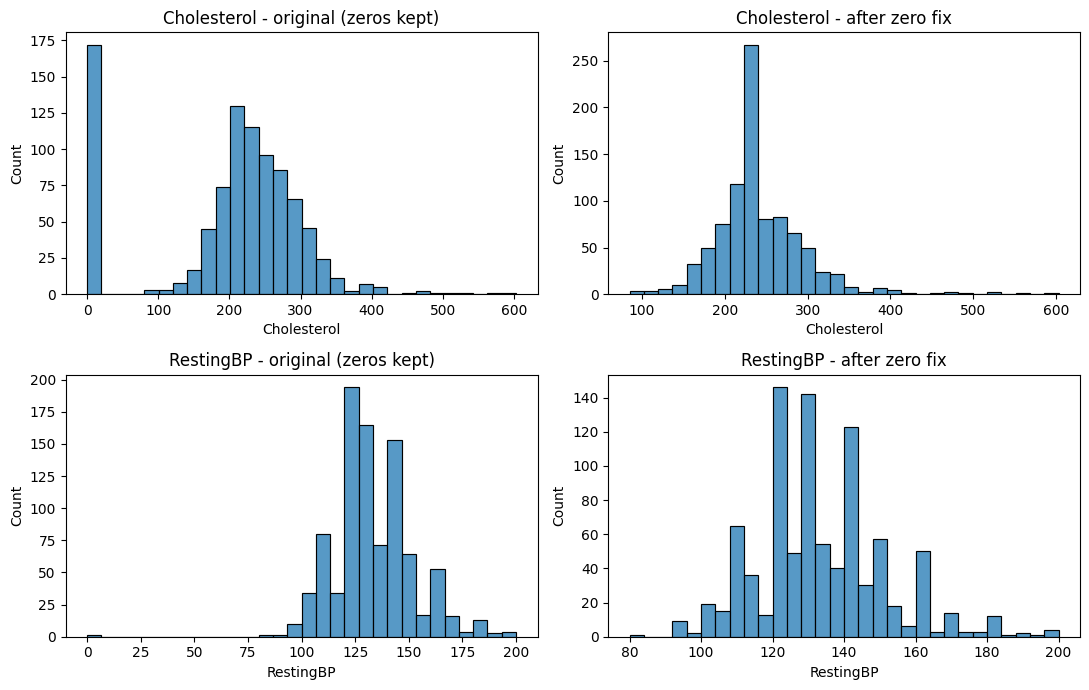

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(X["Cholesterol"],     bins=30, ax=ax[0,0]); ax[0,0].set_title("Cholesterol - original (zeros kept)")
sns.histplot(X_all["Cholesterol"], bins=30, ax=ax[0,1]); ax[0,1].set_title("Cholesterol - after zero fix")
sns.histplot(X["RestingBP"],       bins=30, ax=ax[1,0]); ax[1,0].set_title("RestingBP - original (zeros kept)")
sns.histplot(X_all["RestingBP"],   bins=30, ax=ax[1,1]); ax[1,1].set_title("RestingBP - after zero fix")
plt.tight_layout(); save("02_before_after_zero_fix.png"); plt.show()

### 2.8 Chart: zero cholesterol vs disease
**What it does:** bar chart showing that zero-cholesterol rows are mostly disease cases.

saved: 03_zero_cholesterol_vs_disease.png


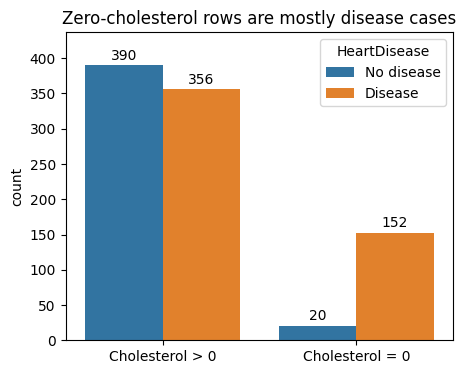

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(x=(df.Cholesterol == 0).map({True: "Cholesterol = 0", False: "Cholesterol > 0"}),
              hue=df.HeartDisease.map({0: "No disease", 1: "Disease"}))
plt.title("Zero-cholesterol rows are mostly disease cases"); plt.xlabel("")
plt.gca().margins(y=0.12)
for c_ in plt.gca().containers: plt.gca().bar_label(c_, fmt="%d", padding=2)
save("03_zero_cholesterol_vs_disease.png"); plt.show()

## 3. Exploratory Data Analysis (EDA)

### 3.1 Class distribution
**What it does:** how many patients have / do not have heart disease. Shows whether the data is balanced.

saved: 04_class_distribution.png


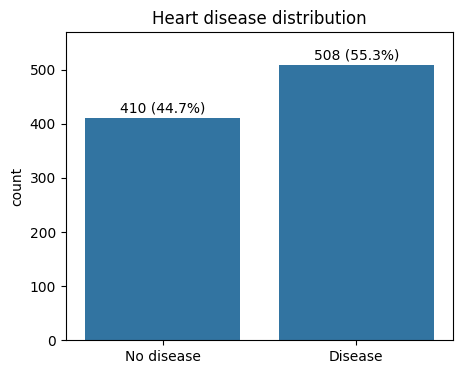

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(x=df["HeartDisease"].map({0: "No disease", 1: "Disease"}))
plt.title("Heart disease distribution"); plt.xlabel("")
ax_ = plt.gca(); ax_.margins(y=0.12)
ax_.bar_label(ax_.containers[0], labels=[f"{int(p_.get_height())} ({p_.get_height() / len(df) * 100:.1f}%)" for p_ in ax_.containers[0]], padding=2)
save("04_class_distribution.png"); plt.show()

### 3.2 Gender vs heart disease
**What it does:** disease counts for male and female patients.

saved: 05_gender_vs_disease.png


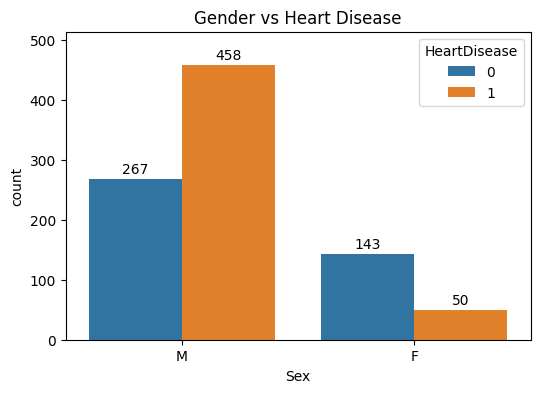

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Sex", hue="HeartDisease", data=df)
plt.title("Gender vs Heart Disease")
plt.gca().margins(y=0.12)
for c_ in plt.gca().containers: plt.gca().bar_label(c_, fmt="%d", padding=2)
save("05_gender_vs_disease.png"); plt.show()

### 3.3 Chest pain type vs heart disease
**What it does:** disease counts for each chest-pain type.

saved: 06_chestpain_vs_disease.png


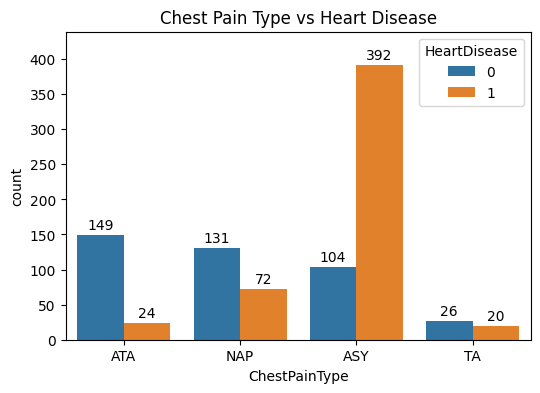

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x="ChestPainType", hue="HeartDisease", data=df)
plt.title("Chest Pain Type vs Heart Disease")
plt.gca().margins(y=0.12)
for c_ in plt.gca().containers: plt.gca().bar_label(c_, fmt="%d", padding=2)
save("06_chestpain_vs_disease.png"); plt.show()

### 3.4 Correlation heatmap
**What it does:** shows which features move together with HeartDisease (uses the cleaned data).

saved: 07_correlation_heatmap.png


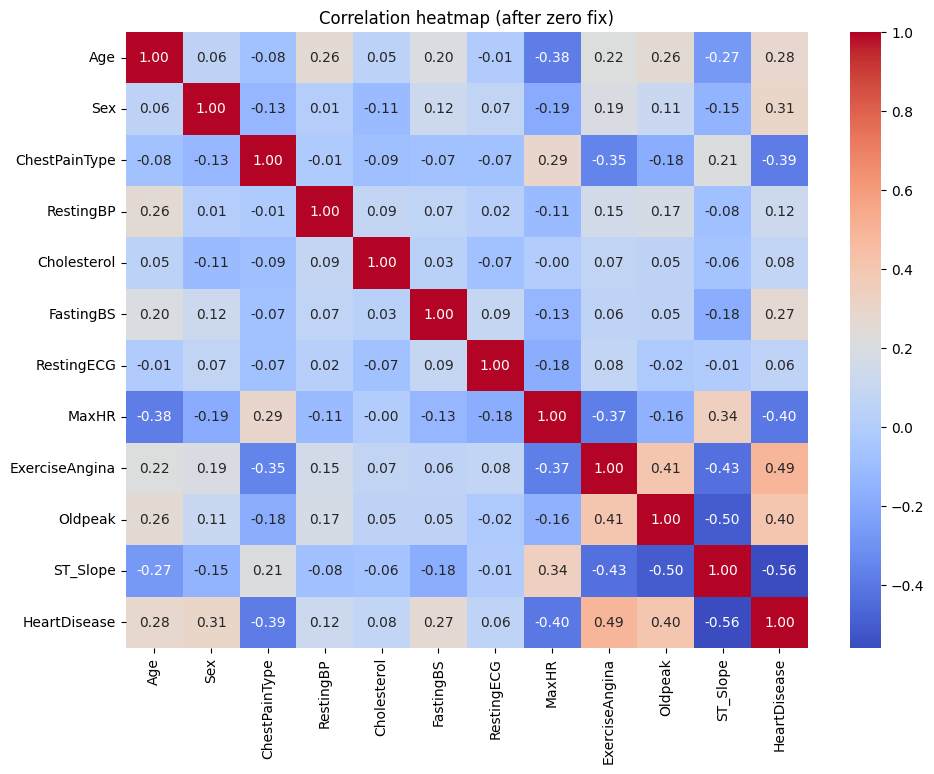

In [ ]:
plt.figure(figsize=(11, 8))
sns.heatmap(pd.concat([X_all, y], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (after zero fix)")
save("07_correlation_heatmap.png"); plt.show()

## 4. Model building and selection

### 4.1 Cross-validation splitter
**What it does:** defines 5-fold cross-validation: training data is cut into 5 parts, the model trains on 4 and checks on 1, five times.

**Why:** gives a more reliable score than a single split.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### 4.2 Define three models
**What it does:** Logistic Regression (simple), Random Forest (many decision trees), XGBoost (boosted trees).

**Why Logistic Regression has a different pipeline:** the label codes (ASY=0, ATA=1 ...) create a false order that a linear model takes literally. So inside its pipeline the categories are one-hot encoded (one yes/no column per category) and the numbers are scaled. Tree models do not need this.

**Viva line:** "Logistic Regression uses one-hot encoding so that it does not treat chest-pain types as ordered numbers; this makes the baseline fair."

In [ ]:
CAT_COLS = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

lr_prep = ColumnTransformer([("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT_COLS),
                             ("num", StandardScaler(), NUM_COLS)])
lr  = Pipeline([("prep", lr_prep), ("clf", LogisticRegression(max_iter=1000))])
rf  = RandomForestClassifier(n_estimators=100, random_state=SEED)
xgb = XGBClassifier(eval_metric="logloss", random_state=SEED)

### 4.3 Tune the Random Forest (GridSearch)
**What it does:** tries 12 combinations of settings (trees, depth, leaf size) using 5-fold CV and keeps the best one.

In [ ]:
grid = GridSearchCV(
    RandomForestClassifier(random_state=SEED),
    {"n_estimators": [100, 300], "max_depth": [None, 5, 10], "min_samples_leaf": [1, 3]},
    scoring="roc_auc", cv=skf, n_jobs=-1)
grid.fit(X_train, y_train)
rf_tuned = grid.best_estimator_
print("Best Random Forest parameters:", grid.best_params_)

Best Random Forest parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 300}


### 4.4 Collect all models in one dictionary
**What it does:** puts the four models together so the next cells can loop over them.

In [ ]:
models = {
    "Logistic Regression":     lr,
    "Random Forest (default)": rf,
    "Random Forest (tuned)":   rf_tuned,
    "XGBoost":                 xgb,
}

### 4.5 Cross-validation score of each model
**What it does:** 5-fold CV ROC-AUC (mean and spread) on training data only.

**Why:** model choice must not use the test set.

In [ ]:
cv_rows = {}
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=skf, scoring="roc_auc")
    cv_rows[name] = {"CV AUC (mean)": s.mean(), "CV AUC (std)": s.std()}
cv_table = pd.DataFrame(cv_rows).T
print(cv_table.round(4).to_string())

                         CV AUC (mean)  CV AUC (std)
Logistic Regression             0.9219        0.0321
Random Forest (default)         0.9257        0.0299
Random Forest (tuned)           0.9305        0.0259
XGBoost                         0.9179        0.0261


### 4.6 Train all models
**What it does:** fits every model on the training data.

In [ ]:
for name, m in models.items():
    m.fit(X_train, y_train)
    print("trained:", name)

trained: Logistic Regression
trained: Random Forest (default)
trained: Random Forest (tuned)
trained: XGBoost


### 4.7 Test-set metrics
**What it does:** accuracy, precision, recall, F1 and ROC-AUC on the 20% unseen test data.

**Viva line:** "Recall matters most here, because missing a disease patient is more dangerous than a false alarm."

In [ ]:
test_rows = {}
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    test_rows[name] = {
        "Test Accuracy":  accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred),
        "Test Recall":    recall_score(y_test, pred),
        "Test F1":        f1_score(y_test, pred),
        "Test ROC-AUC":   roc_auc_score(y_test, prob),
    }
test_table = pd.DataFrame(test_rows).T

### 4.8 Combined comparison table
**What it does:** joins CV scores and test scores into one table (this goes into the report).

In [ ]:
results = cv_table.join(test_table).round(4)
results.index.name = "Model"
print(results.to_string())

                         CV AUC (mean)  CV AUC (std)  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Model                                                                                                                  
Logistic Regression             0.9219        0.0321         0.8859          0.8857       0.9118   0.8986        0.9323
Random Forest (default)         0.9257        0.0299         0.8641          0.8812       0.8725   0.8768        0.9246
Random Forest (tuned)           0.9305        0.0259         0.8750          0.8692       0.9118   0.8900        0.9271
XGBoost                         0.9179        0.0261         0.8424          0.8925       0.8137   0.8513        0.9167


### 4.9 Pick the best model
**What it does:** chooses the model with the highest CV AUC. SHAP's `TreeExplainer` needs a tree model, so the model used for explanation is the best *tree* model.

In [ ]:
best_overall = results["CV AUC (mean)"].idxmax()
tree_names   = [n for n in models if n != "Logistic Regression"]
best_name    = results.loc[tree_names, "CV AUC (mean)"].idxmax()
best_model   = models[best_name]
print(f"Best overall by CV AUC  : {best_overall}")
print(f"Model used for SHAP/LIME: {best_name}")

Best overall by CV AUC  : Random Forest (tuned)
Model used for SHAP/LIME: Random Forest (tuned)


### 4.10 Confusion matrix numbers
**What it does:** counts TN, FP, FN, TP for the best model. **FN** = disease patients predicted as healthy (the dangerous mistake).

In [ ]:
pred_best = best_model.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred_best).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"False negatives (disease predicted as healthy): {fn} of {fn+tp} disease cases")

TN=68  FP=14  FN=9  TP=93
False negatives (disease predicted as healthy): 9 of 102 disease cases


### 4.11 Confusion matrix chart
**What it does:** draws the four numbers as a colored square.

saved: 08_confusion_matrix.png


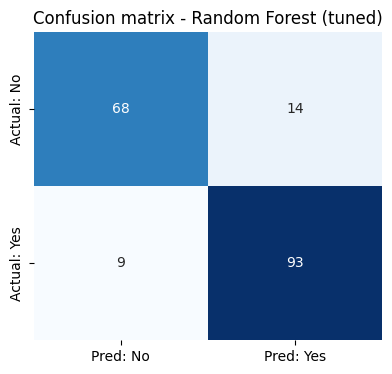

In [ ]:
plt.figure(figsize=(4.5, 4))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
plt.title(f"Confusion matrix - {best_name}")
save("08_confusion_matrix.png"); plt.show()

### 4.12 ROC curves of all models
**What it does:** one curve per model. The more the curve bends to the top-left, the better the model.

saved: 09_roc_curve_comparison.png


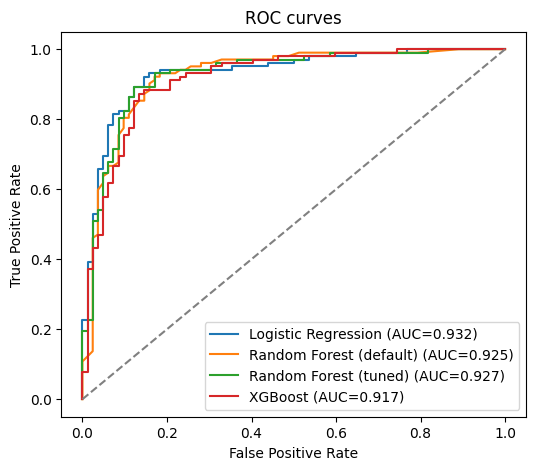

In [ ]:
plt.figure(figsize=(6, 5))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend(); plt.title("ROC curves")
save("09_roc_curve_comparison.png"); plt.show()

### 4.13 Model comparison chart
**What it does:** draws the comparison table (4.8) as a chart. Left: the five test-set metrics for all four models. Right: cross-validated ROC-AUC (dot = mean, line = spread over the 5 folds).

**How to read it:** a model whose bars are higher is better on that metric. If the lines on the right overlap, the models are not clearly different.

**Viva line:** "The chart shows how close the four models are. If the differences are small compared with the cross-validation spread, we do not claim one is clearly superior."

saved: 09b_model_comparison.png


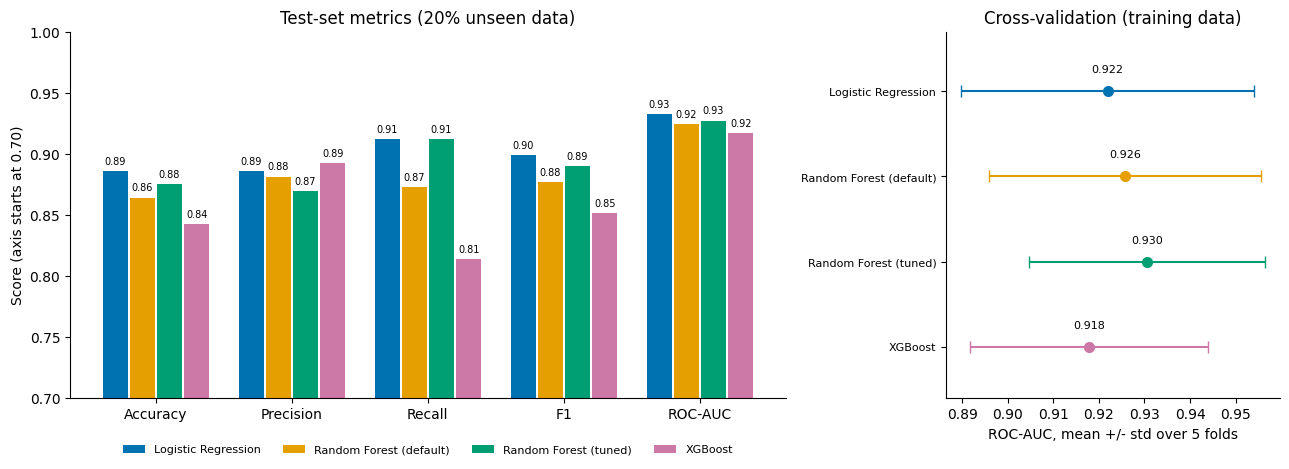

In [ ]:
metric_cols = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"]
metric_lbls = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
palette = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]      # colour-blind-safe, one colour per model
color_of = {name: palette[k] for k, name in enumerate(results.index)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 1.4]})

x, w = np.arange(len(metric_cols)), 0.2
for k, name in enumerate(results.index):
    vals = results.loc[name, metric_cols].values.astype(float)
    pos  = x + (k - (len(results) - 1) / 2) * w
    ax[0].bar(pos, vals, w * 0.92, label=name, color=color_of[name])
    for px, v in zip(pos, vals):
        ax[0].text(px, v + 0.004, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
ax[0].set_xticks(x); ax[0].set_xticklabels(metric_lbls)
ax[0].set_ylim(0.70, 1.0); ax[0].set_ylabel("Score (axis starts at 0.70)")
ax[0].set_title("Test-set metrics (20% unseen data)")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=8)

ypos = np.arange(len(results))[::-1]
for yp, name in zip(ypos, results.index):
    m, s = results.loc[name, "CV AUC (mean)"], results.loc[name, "CV AUC (std)"]
    ax[1].errorbar(m, yp, xerr=s, fmt="o", color=color_of[name], capsize=4, markersize=7)
    ax[1].text(m, yp + 0.22, f"{m:.3f}", ha="center", fontsize=8)
ax[1].set_yticks(ypos); ax[1].set_yticklabels(results.index, fontsize=8)
ax[1].set_xlabel("ROC-AUC, mean +/- std over 5 folds"); ax[1].set_title("Cross-validation (training data)")
ax[1].set_ylim(-0.6, len(results) - 0.3)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save("09b_model_comparison.png"); plt.show()

### 4.14 Save the best model
**What it does:** stores the model, feature list, encoding maps and medians in one file. This file is what a web app will load later (main project).

In [ ]:
pickle.dump({"model": best_model, "features": FEATURES, "maps": MAPS, "medians": medians,
             "risk_cutoffs": (LOW_CUT, HIGH_CUT)},
            open("heart_model.pkl", "wb"))
print("saved: heart_model.pkl")

saved: heart_model.pkl


### 4.15 Confidence intervals for the test metrics
**What it does:** the test set has only 184 patients, so every metric is uncertain. This cell gives a 95% Wilson confidence interval for accuracy, recall, specificity and precision of the best model.

**Why:** a score such as "recall 91.2%" is an estimate; the interval shows the range the true value is likely to lie in.

**Viva line:** "With 184 test patients the intervals are wide, so small differences between the models should not be over-interpreted."

In [ ]:
def wilson(k, n):
    r = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return r.low, r.high

n_test = len(y_test)
parts = {"Accuracy": (tp + tn, n_test), "Recall (sensitivity)": (tp, tp + fn),
         "Specificity": (tn, tn + fp), "Precision": (tp, tp + fp)}
ci_table = pd.DataFrame({m: {"Value": k / n, "95% CI low": wilson(k, n)[0], "95% CI high": wilson(k, n)[1]}
                         for m, (k, n) in parts.items()}).T.round(3)
print(f"Test set: {n_test} patients | model: {best_name}")
print(ci_table.to_string())

Test set: 184 patients | model: Random Forest (tuned)
                      Value  95% CI low  95% CI high
Accuracy              0.875       0.819        0.915
Recall (sensitivity)  0.912       0.841        0.953
Specificity           0.829       0.734        0.895
Precision             0.869       0.792        0.920


### 4.16 Calibration of the risk score
**What it does:** (1) Brier score = average squared error of the predicted probabilities (lower is better; it is compared with a model that always predicts the average disease rate). (2) Calibration chart: patients are grouped by predicted score; the dots show how many in each group really have the disease. Dots near the dashed diagonal mean the score can be read as a probability.

**How to read it:** the groups contain few patients, so small deviations from the diagonal are expected.

**Viva line:** "We checked calibration. If the dots lie close to the diagonal the score can be read as a probability; if they do not, we treat it only as a ranking and say so."

Brier score: 0.104  (reference, always predicting the average disease rate: 0.247)
saved: 09c_calibration_curve.png


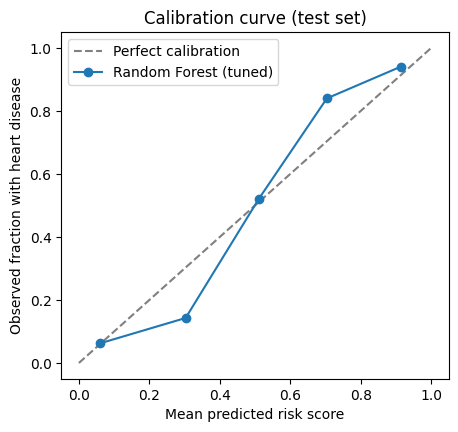

 mean predicted  observed
           0.06      0.06
           0.30      0.14
           0.51      0.52
           0.70      0.84
           0.91      0.94
Average gap between predicted and observed (smaller = better calibrated): 0.07


In [ ]:
prob_test = best_model.predict_proba(X_test)[:, 1]
brier     = brier_score_loss(y_test, prob_test)
brier_ref = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
print(f"Brier score: {brier:.3f}  (reference, always predicting the average disease rate: {brier_ref:.3f})")

frac_pos, mean_pred = calibration_curve(y_test, prob_test, n_bins=5, strategy="uniform")
plt.figure(figsize=(5, 4.5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.plot(mean_pred, frac_pos, "o-", label=best_name)
plt.xlabel("Mean predicted risk score"); plt.ylabel("Observed fraction with heart disease")
plt.title("Calibration curve (test set)"); plt.legend()
save("09c_calibration_curve.png"); plt.show()
print(pd.DataFrame({"mean predicted": mean_pred, "observed": frac_pos}).round(2).to_string(index=False))
print(f"Average gap between predicted and observed (smaller = better calibrated): {np.abs(frac_pos - mean_pred).mean():.2f}")

### 4.17 Threshold table (recall vs false alarms)
**What it does:** shows what happens if we call a patient "disease" at a score of 0.30, 0.40, 0.50 or 0.60 instead of only 0.50.

**Why:** missing a disease patient (FN) is more dangerous than a false alarm (FP). A lower threshold catches more patients but raises the false alarms.

**Viva line:** "The default threshold 0.5 is not the only choice; lowering it increases recall at the cost of more false alarms."

In [ ]:
rows = []
for t in [0.30, 0.40, 0.50, 0.60]:
    pr = (prob_test >= t).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(y_test, pr).ravel()  # TN, FP, FN, TP
    rows.append({"Threshold": t, "FN (missed)": f_n, "FP (false alarm)": f_p, "Recall": t_p / (t_p + f_n),
                 "Specificity": t_n / (t_n + f_p), "Precision": t_p / (t_p + f_p), "Accuracy": (t_n + t_p) / len(y_test)})
threshold_table = pd.DataFrame(rows).set_index("Threshold").round(3)
print(threshold_table.to_string())

           FN (missed)  FP (false alarm)  Recall  Specificity  Precision  Accuracy
Threshold                                                                         
0.3                  5                26   0.951        0.683      0.789     0.832
0.4                  6                19   0.941        0.768      0.835     0.864
0.5                  9                14   0.912        0.829      0.869     0.875
0.6                 18                 8   0.824        0.902      0.913     0.859


### 4.18 Risk levels: Low / Moderate / High
**What it does:** turns the risk score into three levels: **Low** (< 0.30), **Moderate** (0.30 to 0.70) and **High** (> 0.70). The table and chart show, on the test set, how many patients fall in each level and what share of them really has heart disease.

**Why:** a score of 0.51 and a score of 0.99 should not both be just "High". The cut-offs are chosen for this project (not a medical standard); the table justifies them: the disease rate should rise clearly from Low to High.

**Viva line:** "The three levels are chosen by us; the test-set table shows whether the disease rate really rises from Low to High."

          patients  with_disease  disease_rate
level                                         
Low             61             5           8.2
Moderate        42            23          54.8
High            81            74          91.4
Disease rate rises from Low to High: True
saved: 09d_risk_levels.png


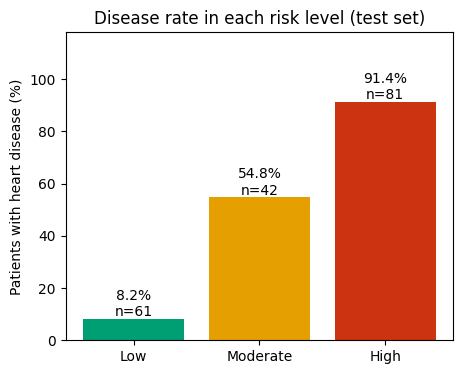

In [ ]:
def risk_level(prob):
    return "Low" if prob < LOW_CUT else ("Moderate" if prob <= HIGH_CUT else "High")

lv = pd.DataFrame({"level": [risk_level(p) for p in prob_test], "disease": y_test.values})
level_table = (lv.groupby("level").agg(patients=("disease", "size"), with_disease=("disease", "sum"),
                                       disease_rate=("disease", "mean")).reindex(["Low", "Moderate", "High"]))
level_table["disease_rate"] = (level_table["disease_rate"] * 100).round(1)
level_table = level_table.fillna(0)          # a level with no patients shows 0
level_table[["patients", "with_disease"]] = level_table[["patients", "with_disease"]].astype(int)
print(level_table.to_string())
rates = level_table.loc[level_table.patients > 0, "disease_rate"].tolist()
print("Disease rate rises from Low to High:", rates == sorted(rates))

plt.figure(figsize=(5, 4))
bars = plt.bar(level_table.index, level_table["disease_rate"], color=["#009E73", "#E69F00", "#CC3311"])
for b_, r_, n_ in zip(bars, level_table["disease_rate"], level_table["patients"]):
    plt.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 1, f"{r_:.1f}%\nn={n_}", ha="center", fontsize=10)
plt.ylim(0, 118); plt.ylabel("Patients with heart disease (%)")
plt.title("Disease rate in each risk level (test set)")
save("09d_risk_levels.png"); plt.show()

## 5. SHAP: global and local explanation

### 5.1 Helper functions for SHAP output
**What it does:** different SHAP versions return the values in different shapes. These two small functions always give us the "Heart Disease" class values.

In [ ]:
def shap_class1(sv):
    # works for old (list) and new (3-D array) SHAP outputs
    if isinstance(sv, list):
        return np.asarray(sv[1])
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

def base_class1(ev):
    ev = np.atleast_1d(ev)
    return float(ev[1] if len(ev) > 1 else ev[0])

### 5.2 Helper functions: SHAP / LIME numbers to plain English
**What it does:** `readable()` turns an encoded number back into the original word (0 / 1 -> F / M, 0 -> ASY ...). `explain_in_words()` takes the top 3 factors that push the risk UP and the top 3 that pull it DOWN and writes them as one sentence. The same functions are used for SHAP and for LIME.

**Why:** a chart is easy for a data scientist, but not for a doctor or an examiner. Under every chart we give the same message in plain English.

**Viva line:** "Every chart has a plain-English explanation under it, so a non-technical person can also understand why the model gave that risk."

In [ ]:
INV_MAPS = {col: {v: k for k, v in m.items()} for col, m in MAPS.items()}

def readable(feature, value):
    if isinstance(value, str):          # already a word (M, ASY, Flat ...)
        return value
    if feature in INV_MAPS:
        return INV_MAPS[feature][int(value)]
    return int(value) if float(value).is_integer() else round(float(value), 2)

def words(feats, row):
    return ", ".join(f"{f} = {readable(f, row[f])}" for f in feats)

def explain_in_words(vec, row, method, top_n=3):
    imp  = pd.Series(vec, index=FEATURES)
    up   = imp[imp > 0].sort_values(ascending=False).head(top_n).index
    down = imp[imp < 0].sort_values().head(top_n).index
    text  = f"{method} explanation: "
    text += f"the factors that push the risk UP are {words(up, row)}. " if len(up) else "no factor pushes the risk up. "
    text += f"The factors that pull the risk DOWN are {words(down, row)}." if len(down) else "No factor pulls the risk down."
    return text

### 5.3 Calculate SHAP values for all patients
**What it does:** for every patient and every feature, SHAP gives a number: how much that feature pushed the risk up (+) or down (-).

In [ ]:
explainer = shap.TreeExplainer(best_model)
sv_all    = shap_class1(explainer.shap_values(X_all, check_additivity=False))
base_val  = base_class1(explainer.expected_value)
print("SHAP values shape (patients x features):", sv_all.shape)

SHAP values shape (patients x features): (918, 11)


### 5.4 Global feature importance table
**What it does:** average absolute SHAP value per feature = which features matter most overall.

In [ ]:
mean_abs = pd.Series(np.abs(sv_all).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print(mean_abs.round(4).to_string())

ST_Slope          0.1838
ChestPainType     0.1064
ExerciseAngina    0.0652
Oldpeak           0.0464
MaxHR             0.0443
Sex               0.0350
FastingBS         0.0254
Cholesterol       0.0218
Age               0.0210
RestingBP         0.0132
RestingECG        0.0053


### 5.5 SHAP beeswarm chart (global)
**What it does:** each dot is a patient. Red = high feature value, blue = low. Left/right = pushes risk down/up.

saved: 10_shap_beeswarm_global.png


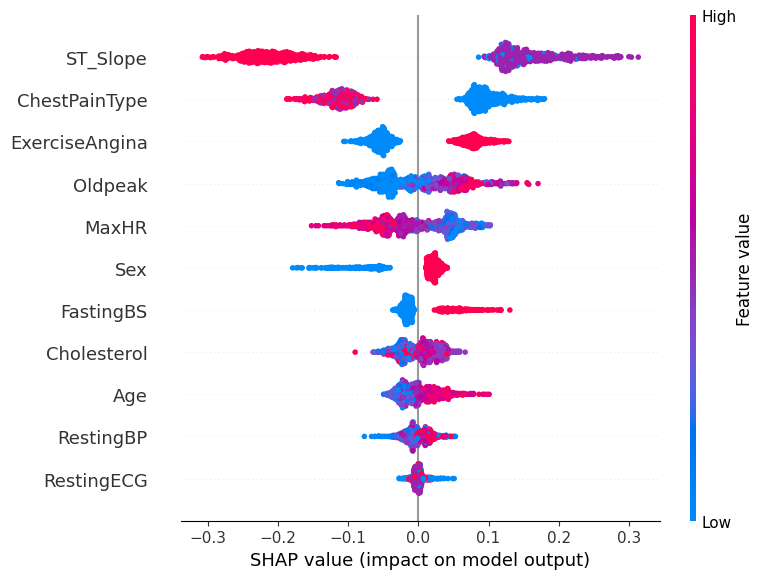

In [ ]:
shap.summary_plot(sv_all, X_all, show=False)
save("10_shap_beeswarm_global.png"); plt.show()

### 5.6 Global importance in plain English
**What it does:** reads the importance table and states in one sentence which features the model relies on most, and which least.

In [ ]:
top3 = list(mean_abs.index[:3])
print(f"In simple words: overall, the model relies most on {top3[0]}, {top3[1]} and {top3[2]} to decide the heart disease risk.")
print(f"The least important feature is {mean_abs.index[-1]}.")

In simple words: overall, the model relies most on ST_Slope, ChestPainType and ExerciseAngina to decide the heart disease risk.
The least important feature is RestingECG.


### 5.7 SHAP waterfall chart (one patient)
**What it does:** explains the prediction for patient 0, feature by feature, from the average risk to the final risk.

saved: 11_shap_waterfall_patient0.png


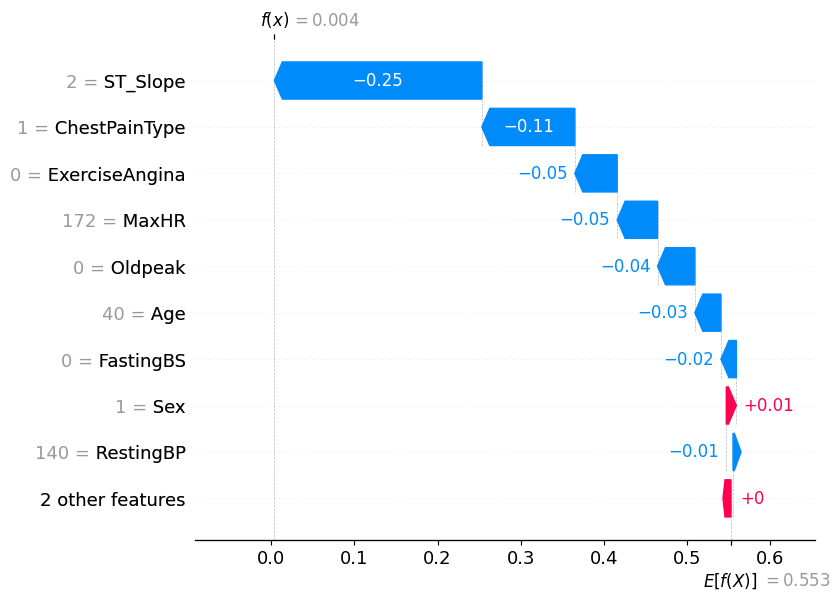

In [ ]:
i = 0
shap.plots.waterfall(shap.Explanation(values=sv_all[i], base_values=base_val,
                                      data=X_all.iloc[i].values, feature_names=FEATURES), show=False)
save("11_shap_waterfall_patient0.png"); plt.show()

### 5.8 Patient 0 in plain English (SHAP)
**What it does:** says the same thing as the waterfall chart, in words: the risk score and level, the factors that push it up and the factors that pull it down.

**Viva line:** "The waterfall chart shows the SHAP values; the sentence under it gives the same information for a person who does not read charts."

In [ ]:
prob0 = float(best_model.predict_proba(X_all.iloc[[i]])[0, 1])
print(f"Patient {i}: risk score {prob0:.2f} -> {risk_level(prob0)} risk.")
print(explain_in_words(sv_all[i], X_all.iloc[i], "SHAP"))

Patient 0: risk score 0.00 -> Low risk.
SHAP explanation: the factors that push the risk UP are Sex = M, Cholesterol = 289. The factors that pull the risk DOWN are ST_Slope = Up, ChestPainType = ATA, ExerciseAngina = N.


## 6. Our own experiment: does the zero-fix change the explanation?
Same Random Forest, same split. Only the zero values differ.

### 6.1 Define the importance function
**What it does:** trains a Random Forest on the given data and returns its mean |SHAP| per feature.

In [ ]:
def shap_importance(Xtr, Xexplain):
    m = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(Xtr, y_train)
    sv = shap_class1(shap.TreeExplainer(m).shap_values(Xexplain, check_additivity=False))
    return pd.Series(np.abs(sv).mean(axis=0), index=FEATURES)

### 6.2 Run it twice: zeros kept vs zeros fixed
**What it does:** one model with the raw zeros, one with the fixed data.

In [ ]:
imp_before = shap_importance(X_train_raw, X)       # zeros kept
imp_after  = shap_importance(X_train,     X_all)   # zeros fixed

### 6.3 Compare the rankings
**What it does:** table of feature ranks before and after, and the Cholesterol rank change.

**Viva line:** "The explanation itself depends on data quality: fixing hidden zeros changes how important Cholesterol looks."

In [ ]:
cmp = pd.DataFrame({
    "rank_before":     imp_before.rank(ascending=False).astype(int),
    "rank_after":      imp_after.rank(ascending=False).astype(int),
    "meanSHAP_before": imp_before.round(4),
    "meanSHAP_after":  imp_after.round(4),
}).sort_values("rank_before")
print(cmp.to_string())

rb, ra = cmp.loc["Cholesterol", "rank_before"], cmp.loc["Cholesterol", "rank_after"]
print(f"\nCholesterol SHAP rank: {rb} (zeros kept)  ->  {ra} (zeros fixed)")

                rank_before  rank_after  meanSHAP_before  meanSHAP_after
ST_Slope                  1           1           0.1885          0.1884
ChestPainType             2           2           0.0907          0.0979
ExerciseAngina            3           3           0.0647          0.0671
Oldpeak                   4           4           0.0542          0.0519
Cholesterol               5           8           0.0488          0.0255
MaxHR                     6           5           0.0427          0.0509
Sex                       7           6           0.0376          0.0389
Age                       8           9           0.0233          0.0232
FastingBS                 9           7           0.0217          0.0300
RestingBP                10          10           0.0178          0.0174
RestingECG               11          11           0.0096          0.0086

Cholesterol SHAP rank: 5 (zeros kept)  ->  8 (zeros fixed)


### 6.4 Before/after chart
**What it does:** two bar charts side by side, Cholesterol in red.

saved: 12_cholesterol_before_after_shap.png


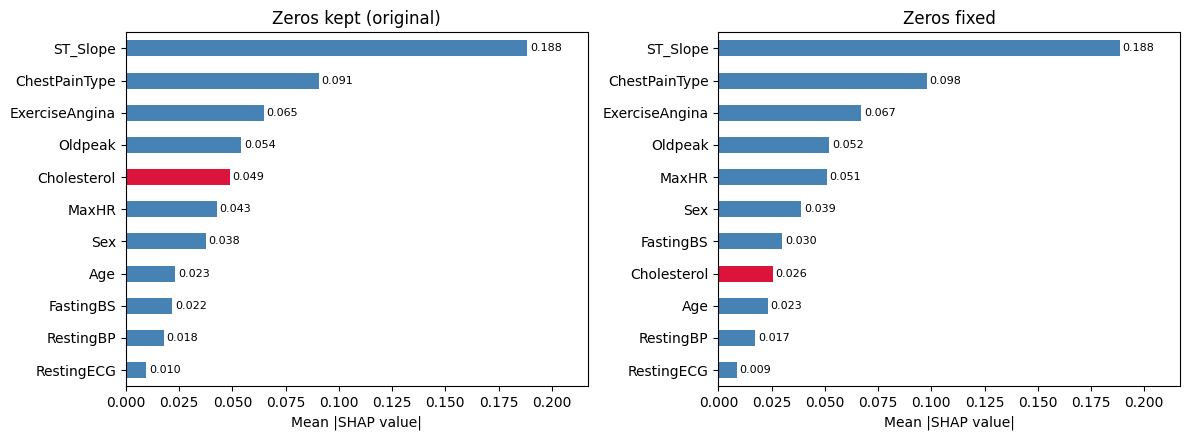

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for a, (title, s) in zip(ax, [("Zeros kept (original)", imp_before), ("Zeros fixed", imp_after)]):
    s = s.sort_values()
    s.plot.barh(ax=a, color=["crimson" if f == "Cholesterol" else "steelblue" for f in s.index])
    a.bar_label(a.containers[0], fmt="%.3f", padding=2, fontsize=8); a.margins(x=0.15)
    a.set_title(title); a.set_xlabel("Mean |SHAP value|")
plt.tight_layout(); save("12_cholesterol_before_after_shap.png"); plt.show()

### 6.5 Cholesterol result in plain English
**What it does:** states in one sentence whether Cholesterol became more or less important after the zero-fix (rank 1 = most important, so a smaller rank number means more important).

In [ ]:
if ra < rb:
    change = f"moved UP from rank {rb} to rank {ra} (became more important)"
elif ra > rb:
    change = f"moved DOWN from rank {rb} to rank {ra} (became less important)"
else:
    change = f"stayed at rank {ra}"
print(f"In simple words: after fixing the zero values, Cholesterol {change} in the SHAP importance list.")

In simple words: after fixing the zero values, Cholesterol moved DOWN from rank 5 to rank 8 (became less important) in the SHAP importance list.


### 6.6 Does the zero-fix change the accuracy?
**What it does:** trains the tuned Random Forest 10 times (10 random seeds) on three versions of the data and compares accuracy, ROC-AUC and recall on the test set: (1) zeros kept, (2) zeros replaced by the median (our method), (3) zeros replaced by the median **plus** a yes/no column "Chol_missing".

**Why:** the zero rows are not random (most are disease cases), so a model can use "Cholesterol = 0" as a shortcut. Median fill removes the shortcut; the extra column gives the information back in an honest form.

**How to read it:** a small drop from (1) to (2) is expected, because the shortcut is gone. Compare the drop with the SD (seed-to-seed spread).

**Viva line:** "Fixing the zeros removes the Cholesterol = 0 shortcut. We measured the effect on accuracy over 10 seeds and report it as it came out, together with the seed-to-seed spread."

In [ ]:
def fit_eval(Xa, Xb, seed):
    m  = RandomForestClassifier(random_state=seed, **grid.best_params_).fit(Xa, y_train)
    pr = m.predict(Xb)
    return accuracy_score(y_test, pr), roc_auc_score(y_test, m.predict_proba(Xb)[:, 1]), recall_score(y_test, pr)

def with_flag(data_raw):
    d = fix_zeros(data_raw)
    d["Chol_missing"] = (data_raw["Cholesterol"] == 0).astype(int).values
    return d

variants = {
    "Zeros kept (no fix)":       (X_train_raw, X_test_raw),
    "Median fix (our method)":   (X_train, X_test),
    "Median fix + missing flag": (with_flag(X_train_raw), with_flag(X_test_raw)),
}
rows = {}
for name, (Xa, Xb) in variants.items():
    r = np.array([fit_eval(Xa, Xb, s) for s in range(N_SEEDS)])
    rows[name] = {"Accuracy": r[:, 0].mean(), "Acc SD": r[:, 0].std(),
                  "ROC-AUC":  r[:, 1].mean(), "AUC SD": r[:, 1].std(),
                  "Recall":   r[:, 2].mean(), "Recall SD": r[:, 2].std()}
zero_fix_table = pd.DataFrame(rows).T.round(4)
zero_fix_table.to_csv("16_zero_fix_accuracy.csv")
print(zero_fix_table.to_string())

a_keep, a_fix, a_flag = zero_fix_table["Accuracy"].values
sd_max = zero_fix_table["Acc SD"].max()
diff = a_fix - a_keep
verdict = ("This is within about two seed-to-seed SDs, so no clear accuracy change is visible."
           if abs(diff) <= 2 * sd_max else
           "This is larger than about two seed-to-seed SDs, so it is a real difference and not random variation.")
print(f"\nIn simple words: replacing the zeros with the median changed the test accuracy by {diff*100:+.1f} percentage points "
      f"(zeros kept {a_keep:.3f} -> median fix {a_fix:.3f}; seed-to-seed SD about {sd_max:.3f}). {verdict} "
      f"With the extra missing-value flag the accuracy is {a_flag:.3f}.")

                           Accuracy  Acc SD  ROC-AUC  AUC SD  Recall  Recall SD
Zeros kept (no fix)          0.8918  0.0062   0.9300  0.0018  0.9245     0.0063
Median fix (our method)      0.8799  0.0045   0.9263  0.0016  0.9118     0.0098
Median fix + missing flag    0.8957  0.0072   0.9316  0.0011  0.9304     0.0092

In simple words: replacing the zeros with the median changed the test accuracy by -1.2 percentage points (zeros kept 0.892 -> median fix 0.880; seed-to-seed SD about 0.007). This is within about two seed-to-seed SDs, so no clear accuracy change is visible. With the extra missing-value flag the accuracy is 0.896.


### 6.7 Is the Cholesterol rank change stable? (10 seeds)
**What it does:** repeats the experiment of 6.2 to 6.5 with 10 different random seeds and records the SHAP rank of Cholesterol each time (zeros kept vs zeros fixed). (Takes a minute or two.)

**Why:** one Random Forest run can give a lucky rank. If Cholesterol moves down in almost every seed, the finding is reliable.

**Viva line:** "We repeated the experiment with 10 seeds, so the Cholesterol result is reported as a mean and spread, not as one lucky run."

 seed  rank_before  rank_after
    0          4.0         8.0
    1          4.0         9.0
    2          5.0         8.0
    3          4.0         8.0
    4          5.0         9.0
    5          6.0         9.0
    6          5.0         8.0
    7          5.0         8.0
    8          6.0         8.0
    9          5.0         7.0

Cholesterol rank, zeros kept : 4.9 +/- 0.7
Cholesterol rank, zeros fixed: 8.2 +/- 0.6
Moved down (less important) in 10 of 10 seeds
saved: 12b_cholesterol_rank_seeds.png


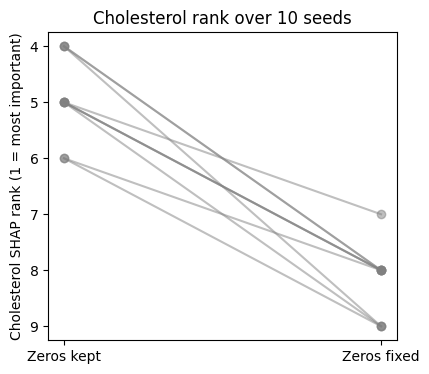

In [ ]:
def shap_importance_seed(Xtr, Xexplain, seed):
    m  = RandomForestClassifier(n_estimators=100, random_state=seed).fit(Xtr, y_train)
    sv = shap_class1(shap.TreeExplainer(m).shap_values(Xexplain, check_additivity=False))
    return pd.Series(np.abs(sv).mean(axis=0), index=FEATURES)

rank_rows = []
for s in range(N_SEEDS):
    rb_s = shap_importance_seed(X_train_raw, X,     s).rank(ascending=False)["Cholesterol"]
    ra_s = shap_importance_seed(X_train,     X_all, s).rank(ascending=False)["Cholesterol"]
    rank_rows.append({"seed": s, "rank_before": rb_s, "rank_after": ra_s})
chol_ranks = pd.DataFrame(rank_rows)
chol_ranks.to_csv("17_cholesterol_rank_over_seeds.csv", index=False)
print(chol_ranks.to_string(index=False))
print(f"\nCholesterol rank, zeros kept : {chol_ranks.rank_before.mean():.1f} +/- {chol_ranks.rank_before.std():.1f}")
print(f"Cholesterol rank, zeros fixed: {chol_ranks.rank_after.mean():.1f} +/- {chol_ranks.rank_after.std():.1f}")
print(f"Moved down (less important) in {(chol_ranks.rank_after > chol_ranks.rank_before).sum()} of {N_SEEDS} seeds")

plt.figure(figsize=(4.5, 4))
for _, r in chol_ranks.iterrows():
    plt.plot([0, 1], [r.rank_before, r.rank_after], "o-", color="gray", alpha=0.5)
plt.xticks([0, 1], ["Zeros kept", "Zeros fixed"]); plt.ylabel("Cholesterol SHAP rank (1 = most important)")
plt.gca().invert_yaxis(); plt.title(f"Cholesterol rank over {N_SEEDS} seeds")
save("12b_cholesterol_rank_seeds.png"); plt.show()

### 6.8 Cholesterol rank over seeds in plain English
**What it does:** one sentence with the average rank before and after the fix.

In [ ]:
m_b, m_a = chol_ranks.rank_before.mean(), chol_ranks.rank_after.mean()
n_down   = int((chol_ranks.rank_after > chol_ranks.rank_before).sum())
print(f"In simple words: over {N_SEEDS} seeds, Cholesterol had an average SHAP rank of {m_b:.1f} with the zeros kept "
      f"and {m_a:.1f} after the fix, and it became less important in {n_down} of {N_SEEDS} seeds.")

In simple words: over 10 seeds, Cholesterol had an average SHAP rank of 4.9 with the zeros kept and 8.2 after the fix, and it became less important in 10 of 10 seeds.


## 7. LIME: local explanation

### 7.1 Tell LIME which features are categories
**What it does:** marks Sex, ChestPainType etc. as categories, and defines how LIME asks the model for probabilities.

In [ ]:
CAT_FEATURES = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope", "FastingBS"]
cat_idx = [FEATURES.index(c) for c in CAT_FEATURES]

def predict_fn(arr):
    return best_model.predict_proba(pd.DataFrame(arr, columns=FEATURES))

### 7.2 LIME helper functions
**What it does:** `make_lime` builds an explainer (with a fixed seed). `lime_weights` explains one patient and returns the 11 weights.

In [ ]:
def make_lime(seed=SEED):
    return LimeTabularExplainer(
        X_train.values, feature_names=FEATURES, class_names=["No Disease", "Heart Disease"],
        categorical_features=cat_idx, mode="classification", random_state=seed)

def lime_weights(lime_explainer, row):
    exp = lime_explainer.explain_instance(row, predict_fn, num_features=len(FEATURES), labels=(1,))
    w = np.zeros(len(FEATURES))
    for idx, wt in exp.as_map()[1]:
        w[idx] = wt
    return w, exp

### 7.3 Create the LIME explainer
**What it does:** builds one explainer that we reuse for all patients.

In [ ]:
lime_exp = make_lime()

### 7.4 LIME explanation for patient 0
**What it does:** LIME builds a small simple model around this patient and shows which features pushed the prediction.

saved: 13_lime_explanation_patient0.png


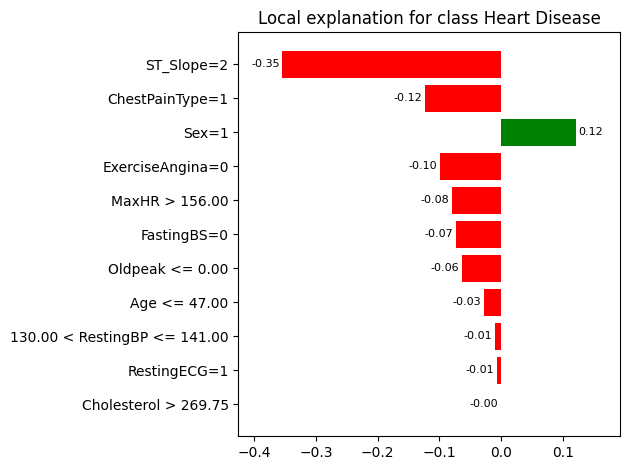

In [ ]:
w0, exp0 = lime_weights(lime_exp, X_all.iloc[0].values)
exp0.as_pyplot_figure(label=1)
ax_ = plt.gca(); ax_.margins(x=0.15)
for c_ in ax_.containers: ax_.bar_label(c_, fmt="%.2f", padding=2, fontsize=8)
plt.tight_layout()
save("13_lime_explanation_patient0.png"); plt.show()

### 7.5 Patient 0 in plain English (LIME)
**What it does:** same as the LIME chart (green bars raise the risk, red bars lower it), written as a sentence in the same format as the SHAP sentence.

**Viva line:** "SHAP and LIME are written in the same sentence format, so they are easy to compare."

In [ ]:
print(explain_in_words(w0, X_all.iloc[0], "LIME"))

LIME explanation: the factors that push the risk UP are Sex = M. The factors that pull the risk DOWN are ST_Slope = Up, ChestPainType = ATA, ExerciseAngina = N.


## 8. SHAP vs LIME agreement

### 8.1 Agreement helper functions
**What it does:** `topk` = the top-5 features of an explanation. `agreement` = how many of the top-5 are shared, plus Spearman and Kendall rank correlations.

In [ ]:
def topk(v, k=TOP_K):
    return set(np.argsort(-np.abs(v))[:k])

def agreement(shap_vec, lime_vec):
    ov  = len(topk(shap_vec) & topk(lime_vec))
    rho = stats.spearmanr(np.abs(shap_vec), np.abs(lime_vec))[0]
    tau = stats.kendalltau(np.abs(shap_vec), np.abs(lime_vec))[0]
    return ov, ov / TOP_K * 100, rho, tau

names = lambda s: [FEATURES[j] for j in sorted(s)]

### 8.2 Agreement for patient 0 and the chance baseline
**What it does:** compares the SHAP and LIME top-5 for one patient. The chance baseline tells how much two *random* top-5 lists would overlap.

**Viva line:** "A result is meaningful only if it is clearly above the chance baseline."

In [ ]:
ov, pct, rho, tau = agreement(sv_all[0], w0)
print("Patient 0")
print("  SHAP top-5:", names(topk(sv_all[0])))
print("  LIME top-5:", names(topk(w0)))
print(f"  Overlap {ov}/{TOP_K} = {pct:.0f}% | Spearman {rho:.2f} | Kendall tau {tau:.2f}")

chance = TOP_K / len(FEATURES) * 100
print(f"\nChance baseline: random top-{TOP_K} sets out of {len(FEATURES)} features overlap {chance:.1f}% on average")

Patient 0
  SHAP top-5: ['ChestPainType', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']
  LIME top-5: ['Sex', 'ChestPainType', 'MaxHR', 'ExerciseAngina', 'ST_Slope']
  Overlap 4/5 = 80% | Spearman 0.83 | Kendall tau 0.71

Chance baseline: random top-5 sets out of 11 features overlap 45.5% on average


### 8.3 Pick random male and female patients
**What it does:** randomly selects 50 male and 50 female patients.

In [ ]:
rng = np.random.RandomState(SEED)
male_pos   = np.where(X_all["Sex"].values == 1)[0]
female_pos = np.where(X_all["Sex"].values == 0)[0]
selected = {
    "Male":   rng.choice(male_pos,   min(N_PER_GROUP, len(male_pos)),   replace=False),
    "Female": rng.choice(female_pos, min(N_PER_GROUP, len(female_pos)), replace=False),
}
print({g: len(v) for g, v in selected.items()})

{'Male': 50, 'Female': 50}


### 8.4 Agreement for every selected patient
**What it does:** for each patient, gets the LIME weights, compares with SHAP, and stores the scores. (This takes a minute.)

In [ ]:
records = []
for group, positions in selected.items():
    for pos in positions:
        w, _ = lime_weights(lime_exp, X_all.iloc[pos].values)
        ov, pct, rho, tau = agreement(sv_all[pos], w)
        records.append({"patient": int(pos), "gender": group, "overlap": ov,
                        "agreement_pct": pct, "spearman": rho, "kendall_tau": tau})
agree_df = pd.DataFrame(records)
agree_df.to_csv("14_multi_patient_validation.csv", index=False)
print("patients compared:", len(agree_df))

patients compared: 100


### 8.5 Summary with 95% confidence interval
**What it does:** average agreement overall, for males and for females, with a bootstrap confidence interval (the likely range of the true average).

In [ ]:
def boot_ci(x, n=2000):
    r = np.random.RandomState(SEED)
    m = [np.mean(r.choice(x, len(x))) for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

summary = []
for g, sub in [("Overall", agree_df)] + [(g, agree_df[agree_df.gender == g]) for g in ["Male", "Female"]]:
    lo, hi = boot_ci(sub["agreement_pct"].values)
    summary.append({"Group": g, "n": len(sub), "Mean agreement %": sub.agreement_pct.mean(),
                    "95% CI low": lo, "95% CI high": hi,
                    "Mean Spearman": sub.spearman.mean(), "Mean Kendall tau": sub.kendall_tau.mean()})
summary = pd.DataFrame(summary).set_index("Group").round(2)
print(summary.to_string())
print(f"\nChance baseline = {chance:.1f}%")
print("Overall CI lower bound above chance?", summary.loc["Overall", "95% CI low"] > chance)

           n  Mean agreement %  95% CI low  95% CI high  Mean Spearman  Mean Kendall tau
Group                                                                                   
Overall  100              80.4        77.8        82.80           0.81              0.68
Male      50              74.0        70.8        77.21           0.76              0.61
Female    50              86.8        84.0        89.60           0.87              0.74

Chance baseline = 45.5%
Overall CI lower bound above chance? True


### 8.6 Is there a gender difference? (statistical test)
**What it does:** Mann-Whitney test. If p < 0.05 the male and female agreement are really different; otherwise the difference is just chance.

In [ ]:
m_pct = agree_df[agree_df.gender == "Male"].agreement_pct.values
f_pct = agree_df[agree_df.gender == "Female"].agreement_pct.values
u, p_mw = stats.mannwhitneyu(m_pct, f_pct, alternative="two-sided")
print(f"Male vs Female: Mann-Whitney U p {'< 0.001' if p_mw < 0.001 else '= ' + format(p_mw, '.3f')} ->",
      "statistically significant (p<0.05)" if p_mw < 0.05 else "NOT statistically significant (p>=0.05)")

Male vs Female: Mann-Whitney U p < 0.001 -> statistically significant (p<0.05)


### 8.7 Gender agreement chart
**What it does:** bars with error lines (confidence interval) and the dashed chance line.

saved: 15_gender_agreement_comparison.png


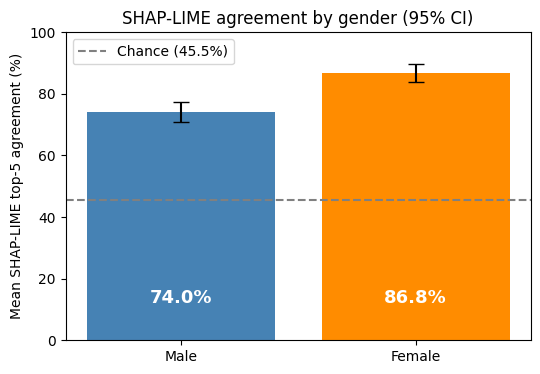

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
g = summary.loc[["Male", "Female"]]
bars_ = ax.bar(g.index, g["Mean agreement %"], color=["steelblue", "darkorange"],
       yerr=[g["Mean agreement %"] - g["95% CI low"], g["95% CI high"] - g["Mean agreement %"]], capsize=6)
for b_ in bars_: ax.text(b_.get_x() + b_.get_width() / 2, 12, f"{b_.get_height():.1f}%", ha="center", color="white", fontsize=13, fontweight="bold")
ax.axhline(chance, ls="--", color="gray", label=f"Chance ({chance:.1f}%)")
ax.set_ylim(0, 100); ax.set_ylabel("Mean SHAP-LIME top-5 agreement (%)"); ax.legend()
ax.set_title("SHAP-LIME agreement by gender (95% CI)")
save("15_gender_agreement_comparison.png"); plt.show()

**Caution (exploratory result):** the male-female difference depends on the model, the sample and the LIME settings, and female patients are only 21% of the data. Report it as an exploratory observation; do not draw a fairness conclusion from it.

### 8.8 LIME self-stability
**What it does:** LIME uses random sampling, so we explain the same patient with 5 different seeds and check whether the top-5 features stay the same. (Slowest cell, 1-2 minutes.)

**Viva line:** "A trustworthy explanation should not change when we only change the random seed."

In [ ]:
rng2 = np.random.RandomState(SEED + 1)
stab = []
for pos in rng2.choice(len(X_all), 20, replace=False):
    sets = [topk(lime_weights(make_lime(seed=100 + s), X_all.iloc[pos].values)[0]) for s in range(5)]
    stab.append(np.mean([len(a & b) / TOP_K for a, b in itertools.combinations(sets, 2)]))
lime_stability = float(np.mean(stab)) * 100
print(f"LIME self-stability (20 patients x 5 seeds): mean top-5 overlap = {lime_stability:.1f}%")

LIME self-stability (20 patients x 5 seeds): mean top-5 overlap = 96.0%


## 9. New patient prediction: web app
Instead of typing the 11 values one by one inside the notebook, the new-patient prediction is done through a web form (Gradio).

### 9.1 Helper functions
**What it does:** three small functions the web page uses. `validate_patient` rejects impossible values (Cholesterol/BP <= 0, wrong spellings), `encode_patient` turns the text values into numbers with the same `MAPS` as training, and `build_report` writes the plain-English explanation from the SHAP and LIME numbers.

In [ ]:
# ---- helper functions used by the web app (same rules as training) ----

def validate_patient(p):
    for col in ZERO_COLS:
        if p[col] <= 0:
            raise ValueError(f"{col} must be a real measurement (> 0). A value of 0 means 'not recorded'.")
    for col, m in MAPS.items():
        if p[col] not in m:
            raise ValueError(f"{col} must be one of {list(m)}")


def encode_patient(p):
    row = pd.DataFrame([p], columns=FEATURES)
    for col, m in MAPS.items():
        row[col] = row[col].map(m)
    return row.astype(float)


def build_report(p, prob, label, s, w, ov):
    imp = pd.Series(s, index=FEATURES)
    up   = imp[imp > 0].sort_values(ascending=False).head(3)
    down = imp[imp < 0].sort_values().head(3)

    level = risk_level(prob)
    lines = [f"PREDICTION: {level.upper()} RISK (estimated risk score {prob:.3f})", ""]
    if len(up):
        lines.append("Factors pushing the risk UP:")
        lines += [f"  - {f} = {p[f]}  (impact +{v:.3f})" for f, v in up.items()]
    if len(down):
        lines.append("Factors pushing the risk DOWN:")
        lines += [f"  - {f} = {p[f]}  (impact -{abs(v):.3f})" for f, v in down.items()]

    r = pd.Series(p)
    simple = f"In simple words: the model gives this patient a {level} heart disease risk (risk score {prob:.2f})."
    lines += ["", simple, explain_in_words(s, r, "SHAP"), explain_in_words(w, r, "LIME"),
              "", f"SHAP and LIME agree on {ov} of their top-{TOP_K} features.",
              "Note: decision-support output only, not a medical diagnosis. The score estimates the likelihood of existing heart disease, not a future event."]
    return "\n".join(lines)

### 9.2 Web app: build the page
**What it does:** shows the new-patient module (Section 9.1) on a web page built with Gradio. The user fills in the 11 values with sliders and drop-down lists and presses **Predict risk**. The page shows the risk level and score, the SHAP waterfall chart, the LIME chart, the SHAP-LIME agreement and the plain-English report (downloadable as a text file). A second tab, **Model insights**, shows the test-set tables and charts already calculated in Sections 4 to 5.

**Why:** typing the answers inside the notebook works only there. The web page can be used by anyone with the link and looks like a real application.

**How:** nothing is trained again. The page re-uses `best_model`, `explainer`, `lime_exp`, `validate_patient`, `encode_patient`, `build_report` and `agreement` from the cells above, so its answer for the same patient is the same as a typed run. Run this cell, then the next one.

**Viva line:** "The web app is only a front end. The model, the validation rules and the SHAP and LIME code are exactly the notebook ones."

In [ ]:
import os, tempfile
import gradio as gr

# ---- charts for the web page (return the figure instead of saving/showing it) ----
def shap_figure(row, s):
    plt.close("all")
    expl = shap.Explanation(values=s, base_values=base_val, data=row.iloc[0].values, feature_names=FEATURES)
    shap.plots.waterfall(expl, show=False)
    fig = plt.gcf()
    fig.set_size_inches(7.5, 5.2)
    fig.patch.set_facecolor("white")
    fig.tight_layout()                                   # keeps the long feature names inside the picture
    return fig


def lime_figure(exp):
    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(7.5, 5)
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    return fig


# ---- result cards (HTML) ----
LEVEL_STYLE = {"Low": ("#22c55e", "Low risk"), "Moderate": ("#f59e0b", "Moderate risk"), "High": ("#ef4444", "High risk")}


def result_card(prob):
    level = risk_level(prob)
    colour, label = LEVEL_STYLE[level]
    pct = max(0.0, min(1.0, prob)) * 100
    return f"""
<div class="risk-card">
  <div class="risk-top">
    <div>
      <div class="risk-label">Predicted heart disease risk</div>
      <div class="risk-level" style="color:{colour}">{label}</div>
    </div>
    <div class="risk-score">{prob:.3f}<span>risk score</span></div>
  </div>
  <div class="risk-bar"><div class="risk-fill" style="width:{pct:.1f}%;background:{colour}"></div>
    <i style="left:{LOW_CUT*100:.0f}%"></i><i style="left:{HIGH_CUT*100:.0f}%"></i></div>
  <div class="risk-scale"><span>Low &lt; {LOW_CUT:.2f}</span><span>Moderate {LOW_CUT:.2f} to {HIGH_CUT:.2f}</span><span>High &gt; {HIGH_CUT:.2f}</span></div>
</div>"""


def agreement_card(s, w, ov, pct):
    chance = TOP_K / len(FEATURES) * 100
    return f"""
<div class="agree-card">
  <div class="agree-title">SHAP and LIME agreement: <b>{ov} of {TOP_K}</b> top features ({pct:.0f}%)</div>
  <div class="agree-row"><span class="tag">SHAP top-{TOP_K}</span>{', '.join(names(topk(s)))}</div>
  <div class="agree-row"><span class="tag">LIME top-{TOP_K}</span>{', '.join(names(topk(w)))}</div>
  <div class="agree-note">A random choice of {TOP_K} out of {len(FEATURES)} features would agree about {chance:.1f}% of the time.</div>
</div>"""

In [ ]:
def predict_ui(age, sex, chest, rbp, chol, fbs, ecg, maxhr, exang, oldpeak, slope):
    try:
        p = {"Age": int(age), "Sex": sex, "ChestPainType": chest, "RestingBP": int(rbp or 0), "Cholesterol": int(chol or 0),
             "FastingBS": int(fbs), "RestingECG": ecg, "MaxHR": int(maxhr), "ExerciseAngina": exang,
             "Oldpeak": float(oldpeak), "ST_Slope": slope}
        validate_patient(p)                              # same rules as in 9.1
    except (ValueError, TypeError) as e:
        # show the problem inside the Result area (clean page, no stuck loading boxes)
        msg = f'<div class="agree-card"><div class="agree-title"><b>Input problem:</b> {e}</div><div class="agree-note">No prediction was made. Correct the value and press <b>Predict risk</b> again.</div></div>'
        return msg, None, None, "", "", None

    row  = encode_patient(p)                             # helper in 9.1
    prob = float(best_model.predict_proba(row)[0, 1])
    s = shap_class1(explainer.shap_values(row, check_additivity=False))[0]
    fig_shap = shap_figure(row, s)
    w, exp = lime_weights(lime_exp, row.iloc[0].values)
    fig_lime = lime_figure(exp)
    ov, pct, rho, tau = agreement(s, w)
    text = build_report(p, prob, int(prob >= 0.5), s, w, ov)   # helper in 9.1
    path = os.path.join(tempfile.mkdtemp(), "patient_report.txt")
    with open(path, "w") as f:
        f.write(text)
    return result_card(prob), fig_shap, fig_lime, agreement_card(s, w, ov, pct), text, path

In [ ]:
# ---- "Model insights" tab: re-uses the tables and numbers already calculated in Sections 4 and 5 ----
_pct = lambda v: f"{v * 100:.1f}%"

web_metrics_df = pd.DataFrame({
    "Metric": list(ci_table.index),
    "Value": [_pct(v) for v in ci_table["Value"]],
    "95% CI (Wilson)": [f"{_pct(lo)} to {_pct(hi)}" for lo, hi in zip(ci_table["95% CI low"], ci_table["95% CI high"])]})

web_threshold_df = pd.DataFrame({
    "Threshold": [f"{t:.2f}" for t in threshold_table.index],
    "Missed (FN)": threshold_table["FN (missed)"].astype(int).values,
    "False alarms (FP)": threshold_table["FP (false alarm)"].astype(int).values,
    "Recall": [_pct(v) for v in threshold_table["Recall"]],
    "Accuracy": [_pct(v) for v in threshold_table["Accuracy"]]})

web_level_df = pd.DataFrame({
    "Risk level": list(level_table.index),
    "Patients": level_table["patients"].astype(int).values,
    "With heart disease": level_table["with_disease"].astype(int).values,
    "Disease rate": [f"{r:.1f}%" for r in level_table["disease_rate"]]})

web_auc = roc_auc_score(y_test, prob_test)


def web_fig_confusion():
    fig, ax = plt.subplots(figsize=(4.6, 4))
    cm = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=18,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["No disease", "Disease"]); ax.set_yticklabels(["No disease", "Disease"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix (test set)")
    fig.tight_layout()
    return fig


def web_fig_calibration():
    frac_pos_, mean_pred_ = calibration_curve(y_test, prob_test, n_bins=5, strategy="uniform")
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.plot(mean_pred_, frac_pos_, "o-", color="#2563eb", label=best_name)
    ax.set_xlabel("Mean predicted risk score"); ax.set_ylabel("Observed fraction with heart disease")
    ax.set_title("Calibration curve (test set)"); ax.legend()
    fig.tight_layout()
    return fig


def web_fig_importance():
    imp_ = mean_abs.sort_values()
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    ax.barh(imp_.index, imp_.values, color="#2563eb")
    ax.set_xlabel("Mean |SHAP value| (average effect on the risk score)")
    ax.set_title("Global feature importance (SHAP)")
    fig.tight_layout()
    return fig

In [ ]:
# ---- the web page (black / blue theme) ----
CSS = """
.gradio-container{background:linear-gradient(135deg,#02030a 0%,#06122e 45%,#0b2d70 100%) fixed !important;color:#e6edff !important;max-width:1250px !important;margin:auto !important}
.gradio-container .block,.gradio-container .form,.gradio-container .panel{background:rgba(255,255,255,.045) !important;border:1px solid rgba(120,160,255,.22) !important;border-radius:16px !important;box-shadow:none !important}
.gradio-container label span,.gradio-container .block-title,.gradio-container .block-label,.gradio-container p,.gradio-container li,.gradio-container h1,.gradio-container h2,.gradio-container h3,.gradio-container td,.gradio-container th{color:#e6edff !important}
.gradio-container input,.gradio-container textarea,.gradio-container select{background:#08122b !important;color:#eaf1ff !important;border:1px solid rgba(120,160,255,.35) !important;border-radius:10px !important}
.gradio-container button.primary,.gradio-container .primary{background:linear-gradient(90deg,#2563eb,#06b6d4) !important;color:#fff !important;border:none !important;font-weight:700 !important;border-radius:12px !important}
.gradio-container button.secondary,.gradio-container .secondary{background:rgba(255,255,255,.08) !important;color:#e6edff !important;border:1px solid rgba(120,160,255,.35) !important;border-radius:12px !important}
.gradio-container .tab-nav button,.gradio-container button[role=tab]{color:#b8c7f2 !important;font-weight:600}
.gradio-container .tab-nav button.selected,.gradio-container button[role=tab][aria-selected=true]{color:#fff !important;border-bottom:2px solid #38bdf8 !important}
.gradio-container .plot-container,.gradio-container .js-plotly-plot,.gradio-container [data-testid=plot] img{background:#ffffff !important;border-radius:12px !important}
.hero{padding:26px 28px;border-radius:20px;border:1px solid rgba(120,160,255,.3);background:linear-gradient(120deg,rgba(37,99,235,.35),rgba(6,182,212,.18) 60%,rgba(2,3,10,.3));margin-bottom:6px}
.hero h1{margin:0 0 6px 0;font-size:30px;font-weight:800;background:linear-gradient(90deg,#ffffff,#7dd3fc);-webkit-background-clip:text;background-clip:text;-webkit-text-fill-color:transparent;color:transparent !important}
.hero p{margin:0;color:#b8c7f2 !important;font-size:15px}
.pill{display:inline-block;margin:10px 8px 0 0;padding:4px 12px;border-radius:999px;font-size:12px;border:1px solid rgba(125,211,252,.5);color:#7dd3fc;background:rgba(14,116,144,.2)}
.risk-card{padding:18px 20px;border-radius:16px;border:1px solid rgba(120,160,255,.3);background:linear-gradient(135deg,rgba(15,23,42,.9),rgba(11,45,112,.55))}
.risk-top{display:flex;justify-content:space-between;align-items:center;gap:12px}
.risk-label{font-size:13px;color:#9db2e6;letter-spacing:.5px;text-transform:uppercase}
.risk-level{font-size:32px;font-weight:800;line-height:1.15}
.risk-score{font-size:34px;font-weight:800;color:#fff;text-align:right}
.risk-score span{display:block;font-size:12px;font-weight:500;color:#9db2e6}
.risk-bar{position:relative;height:12px;border-radius:999px;background:rgba(255,255,255,.12);margin-top:14px;overflow:hidden}
.risk-fill{height:100%;border-radius:999px}
.risk-bar i{position:absolute;top:0;bottom:0;width:2px;background:rgba(255,255,255,.6)}
.risk-scale{display:flex;justify-content:space-between;margin-top:6px;font-size:12px;color:#9db2e6}
.agree-card{padding:14px 18px;border-radius:14px;border:1px solid rgba(120,160,255,.28);background:rgba(8,18,43,.7);color:#e6edff}
.agree-title{font-size:15px;margin-bottom:8px}
.agree-row{font-size:14px;margin:4px 0;color:#d4defa}
.tag{display:inline-block;min-width:92px;margin-right:8px;padding:2px 10px;border-radius:8px;background:rgba(56,189,248,.18);color:#7dd3fc;font-size:12px;font-weight:700}
.agree-note{margin-top:8px;font-size:12px;color:#9db2e6}
.disclaimer{padding:12px 16px;border-radius:12px;border:1px solid rgba(245,158,11,.5);background:rgba(245,158,11,.08);color:#fcd9a0 !important;font-size:13px}
.foot{text-align:center;color:#7f93c9 !important;font-size:12px;margin-top:8px}
.gradio-container .plot-container,.gradio-container [data-testid=plot],.gradio-container [data-testid=plot] img,.gradio-container .plot-container img{height:auto !important;max-height:none !important;object-fit:contain !important;overflow:visible !important}
"""

# ---- white, black-and-white-friendly look (use it for the screenshots that go into the printed report) ----
CSS_PRINT = """
html,body,gradio-app,.gradio-container,.dark,:root{color-scheme:light !important;
--body-background-fill:#ffffff;--background-fill-primary:#ffffff;--background-fill-secondary:#f4f4f4;
--block-background-fill:#ffffff;--block-border-color:#333333;--panel-background-fill:#ffffff;
--block-label-background-fill:#ececec;--block-label-text-color:#111111;--block-title-text-color:#111111;--block-info-text-color:#111111;
--body-text-color:#111111;--body-text-color-subdued:#333333;--input-background-fill:#ffffff;--input-background-fill-focus:#ffffff;
--input-border-color:#333333;--input-placeholder-color:#555555;--border-color-primary:#333333;--border-color-accent:#111111;
--table-even-background-fill:#ffffff;--table-odd-background-fill:#f4f4f4;--table-border-color:#333333;
--neutral-50:#f9fafb;--neutral-100:#f3f4f6;--neutral-200:#e5e7eb;--neutral-300:#d1d5db;--neutral-400:#9ca3af;--neutral-500:#6b7280;
--neutral-600:#4b5563;--neutral-700:#374151;--neutral-800:#1f2937;--neutral-900:#111827;--neutral-950:#0b0f19}
html,body,gradio-app{background:#ffffff !important}
.gradio-container span,.gradio-container b,.gradio-container strong,.gradio-container i,.gradio-container em,.gradio-container label,.gradio-container .wrap,.gradio-container li,.gradio-container ul{color:#111111 !important}
.gradio-container .wrap,.gradio-container .wrap-inner,.gradio-container .secondary-wrap,.gradio-container ul.options,.gradio-container ul.options li{background:#ffffff !important}
.gradio-container .block-label,.gradio-container .label-wrap{background:#ececec !important;color:#111111 !important}
.gradio-container{background:#ffffff !important;color:#111111 !important;max-width:1250px !important;margin:auto !important}
.gradio-container .block,.gradio-container .form,.gradio-container .panel{background:#ffffff !important;border:1px solid #333333 !important;border-radius:12px !important;box-shadow:none !important}
.gradio-container label span,.gradio-container .block-title,.gradio-container .block-label,.gradio-container p,.gradio-container li,.gradio-container h1,.gradio-container h2,.gradio-container h3,.gradio-container td,.gradio-container th{color:#111111 !important}
.gradio-container input,.gradio-container textarea,.gradio-container select{background:#ffffff !important;color:#111111 !important;border:1px solid #333333 !important;border-radius:8px !important}
.gradio-container button.primary,.gradio-container button.primary span,.gradio-container .primary{background:#111111 !important;color:#ffffff !important;border:none !important;font-weight:700 !important;border-radius:10px !important}
.gradio-container button.secondary,.gradio-container .secondary{background:#ffffff !important;color:#111111 !important;border:1px solid #111111 !important;border-radius:10px !important}
.gradio-container .tab-nav button,.gradio-container button[role=tab]{color:#333333 !important;font-weight:600}
.gradio-container .tab-nav button.selected,.gradio-container button[role=tab][aria-selected=true]{color:#000000 !important;border-bottom:2px solid #000000 !important}
.hero{padding:22px 26px;border-radius:14px;border:1px solid #111111;background:#f2f2f2;margin-bottom:6px}
.hero h1{margin:0 0 6px 0;font-size:30px;font-weight:800;background:none;-webkit-text-fill-color:#000000;color:#000000 !important}
.hero p{margin:0;color:#222222 !important;font-size:15px}
.pill{display:inline-block;margin:10px 8px 0 0;padding:4px 12px;border-radius:999px;font-size:12px;border:1px solid #111111;color:#111111;background:#ffffff}
.risk-card{padding:18px 20px;border-radius:14px;border:1.5px solid #111111;background:#ffffff}
.risk-top{display:flex;justify-content:space-between;align-items:center;gap:12px}
.risk-label{font-size:13px;color:#333333;letter-spacing:.5px;text-transform:uppercase}
.risk-level{font-size:32px;font-weight:800;line-height:1.15;color:#000000 !important}
.risk-score{font-size:34px;font-weight:800;color:#000000;text-align:right}
.risk-score span{display:block;font-size:12px;font-weight:500;color:#333333}
.risk-bar{position:relative;height:14px;border-radius:999px;background:#d9d9d9;border:1px solid #111111;margin-top:14px;overflow:hidden}
.risk-fill{height:100%;border-radius:999px;background:#111111 !important}
.risk-bar i{position:absolute;top:0;bottom:0;width:2px;background:#888888}
.risk-scale{display:flex;justify-content:space-between;margin-top:6px;font-size:12px;color:#222222}
.agree-card{padding:14px 18px;border-radius:12px;border:1px solid #333333;background:#ffffff;color:#111111}
.agree-title{font-size:15px;margin-bottom:8px}
.agree-row{font-size:14px;margin:4px 0;color:#111111}
.tag{display:inline-block;min-width:92px;margin-right:8px;padding:2px 10px;border-radius:8px;background:#e6e6e6;border:1px solid #555555;color:#000000;font-size:12px;font-weight:700}
.agree-note{margin-top:8px;font-size:12px;color:#333333}
.disclaimer{padding:12px 16px;border-radius:12px;border:1px solid #111111;background:#f2f2f2;color:#111111 !important;font-size:13px}
.foot{text-align:center;color:#333333 !important;font-size:12px;margin-top:8px}
.gradio-container .plot-container,.gradio-container [data-testid=plot],.gradio-container [data-testid=plot] img,.gradio-container .plot-container img{height:auto !important;max-height:none !important;object-fit:contain !important;overflow:visible !important}
"""

PRINT_MODE = True     # False = black / blue look for the demo.  True = white look for the screenshots in the printed report

HERO = """
<div class="hero">
  <h1>Heart Disease Risk Predictor</h1>
  <p>Enter a patient's details to get a risk level, and see <b>why</b> the model gave it (SHAP and LIME).</p>
  <span class="pill">Tuned Random Forest</span><span class="pill">SHAP + LIME</span><span class="pill">Decision support, not a diagnosis</span>
</div>"""

DISCLAIMER = ('<div class="disclaimer"><b>Decision support only.</b> This prototype was built for a mini project. '
              'It estimates the likelihood of <i>existing</i> heart disease from 11 clinical values. It is not a medical diagnosis '
              'and was not validated on any clinical data outside the public Kaggle dataset.</div>')

SAMPLE = (58, "M", "ASY", 145, 289, 0, "Normal", 120, "Y", 2.0, "Flat")


def build_demo():
    theme = gr.themes.Base(primary_hue="blue", secondary_hue="cyan", neutral_hue="slate")
    with gr.Blocks(theme=theme, css=(CSS_PRINT if PRINT_MODE else CSS), title="Heart Disease Risk Predictor") as demo:
        gr.HTML(HERO)
        with gr.Tabs():
            # ---------------- Tab 1: predict ----------------
            with gr.TabItem("Predict"):
                with gr.Row():
                    with gr.Column(scale=4, min_width=320):
                        gr.Markdown("### Patient details")
                        age = gr.Slider(18, 100, value=SAMPLE[0], step=1, label="Age (years)")
                        sex = gr.Dropdown([("Male", "M"), ("Female", "F")], value=SAMPLE[1], label="Sex")
                        chest = gr.Dropdown([("ASY: asymptomatic (no chest pain)", "ASY"), ("ATA: atypical angina", "ATA"),
                                             ("NAP: non-anginal pain", "NAP"), ("TA: typical angina", "TA")],
                                            value=SAMPLE[2], label="Chest pain type")
                        with gr.Row():
                            rbp = gr.Number(value=SAMPLE[3], precision=0, label="Resting BP (mm Hg)")
                            chol = gr.Number(value=SAMPLE[4], precision=0, label="Cholesterol (mg/dl)")
                        fbs = gr.Dropdown([("No (0)", 0), ("Yes (1)", 1)], value=SAMPLE[5], label="Fasting blood sugar > 120 mg/dl")
                        ecg = gr.Dropdown([("Normal", "Normal"), ("ST-T wave abnormality (ST)", "ST"),
                                           ("Left ventricular hypertrophy (LVH)", "LVH")], value=SAMPLE[6], label="Resting ECG")
                        maxhr = gr.Slider(60, 220, value=SAMPLE[7], step=1, label="Maximum heart rate achieved")
                        exang = gr.Dropdown([("Yes", "Y"), ("No", "N")], value=SAMPLE[8], label="Exercise-induced angina")
                        oldpeak = gr.Slider(-3, 7, value=SAMPLE[9], step=0.1, label="Oldpeak (ST depression)")
                        slope = gr.Dropdown([("Up", "Up"), ("Flat", "Flat"), ("Down", "Down")], value=SAMPLE[10], label="ST slope")
                        inputs = [age, sex, chest, rbp, chol, fbs, ecg, maxhr, exang, oldpeak, slope]
                        with gr.Row():
                            btn = gr.Button("Predict risk", variant="primary")
                            ex = gr.Button("Load sample patient", variant="secondary")
                    with gr.Column(scale=7, min_width=420):
                        gr.Markdown("### Result")
                        out_card = gr.HTML(value='<div class="agree-card">Fill in the details and press <b>Predict risk</b>.</div>')
                        out_agree = gr.HTML()
                        out_shap = gr.Plot(label="SHAP waterfall: how each feature moved the risk score")
                        out_lime = gr.Plot(label="LIME: local explanation (green raises the risk, red lowers it)")
                        out_text = gr.Textbox(label="Plain-English report", lines=20, max_lines=30, interactive=False)
                        out_file = gr.File(label="Download report (.txt)")
                gr.HTML(DISCLAIMER)
                btn.click(predict_ui, inputs=inputs, outputs=[out_card, out_shap, out_lime, out_agree, out_text, out_file])
                ex.click(lambda: list(SAMPLE), inputs=None, outputs=inputs)

            # ---------------- Tab 2: model insights ----------------
            with gr.TabItem("Model insights"):
                gr.Markdown(
                    f"### About this model\n"
                    f"Tuned Random Forest trained on **{len(X_train)}** patients and tested on **{n_test}** unseen patients "
                    f"(80/20 stratified split, seed {SEED}). Test ROC-AUC **{web_auc:.3f}**, Brier score **{brier:.3f}** "
                    f"(always predicting the average rate gives {brier_ref:.3f}).")
                gr.Markdown(
                    f"**Data-quality fix:** {n_chol0} records ({n_chol0 / len(df) * 100:.1f}%) had Cholesterol = 0, which is a hidden missing value. "
                    f"{rate_zero * 100:.1f}% of them have heart disease, against {rate_valid * 100:.1f}% of records with a valid reading. "
                    f"They were replaced with the training-set median ({medians['Cholesterol']:.0f} mg/dl; Resting BP {medians['RestingBP']:.0f} mm Hg), "
                    f"so the model cannot use \"Cholesterol = 0\" as a shortcut for disease.")
                with gr.Row():
                    with gr.Column():
                        gr.Markdown("#### Test-set metrics with 95% confidence intervals")
                        gr.Dataframe(value=web_metrics_df, interactive=False)
                        gr.Markdown("#### What the decision threshold changes")
                        gr.Dataframe(value=web_threshold_df, interactive=False)
                        gr.Markdown("#### Heart disease rate in each risk level")
                        gr.Dataframe(value=web_level_df, interactive=False)
                    with gr.Column():
                        gr.Plot(value=web_fig_importance(), label="Global SHAP importance")
                with gr.Row():
                    gr.Plot(value=web_fig_confusion(), label="Confusion matrix")
                    gr.Plot(value=web_fig_calibration(), label="Calibration curve")
    return demo

**Start the web app.** Run the cell below. It prints a link like `https://xxxx.gradio.live` (works while this notebook is running) and also shows the page under the cell. Use only the sample patient or made-up values, never real patient data.

**For the report screenshots:** in the previous cell set `PRINT_MODE = True`, run that cell and this one again. The page then has a white background and black text, so it prints clearly in black and white. Set it back to `False` for the demo.

If some labels still look pale or the background is dark, open the link with `?__theme=light` at the end (for example `https://xxxx.gradio.live/?__theme=light`).

**Figure 9.2 (error screenshot):** reload the page first (so the result area is empty), type `0` in Cholesterol, press **Predict risk**, and take the screenshot. The message "Input problem: Cholesterol must be a real measurement" is shown in the Result area.

In [ ]:
SHARE_LINK = True      # True = public link for the demo; False = only inside this notebook
demo = build_demo()
demo.queue()
demo.launch(share=SHARE_LINK, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e35f18d91c44c356b3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Numbers for the report

### 10.1 Collect all key numbers in one text file
**What it does:** gathers every important number (data quality, model table, SHAP ranking, agreement, stability) so you can copy them into the report.

In [ ]:
lines = []
lines.append(f"Dataset: {df.shape[0]} rows, {len(FEATURES)} features, duplicates={df.duplicated().sum()}")
lines.append(f"Cholesterol==0: {n_chol0} rows ({n_chol0/len(df):.1%}); heart-disease rate {rate_zero:.1%} (zero) vs {rate_valid:.1%} (valid)")
lines.append(f"RestingBP==0: {n_bp0} row(s); imputation medians: {medians}")
lines.append("")
lines.append("MODEL COMPARISON"); lines.append(results.to_string())
lines.append(f"Best overall (CV AUC): {best_overall} | model used for SHAP/LIME: {best_name}")
lines.append(f"RF tuned params: {grid.best_params_}")
lines.append(f"Confusion matrix ({best_name}): TN={tn} FP={fp} FN={fn} TP={tp}")
lines.append("")
lines.append("SHAP global ranking: " + ", ".join(mean_abs.index[:5]))
lines.append(f"Cholesterol SHAP rank: {rb} (zeros kept) -> {ra} (zeros fixed)")
lines.append("")
lines.append("SHAP-LIME AGREEMENT"); lines.append(summary.to_string())
lines.append(f"Chance baseline: {chance:.1f}% | Male vs Female Mann-Whitney p = {p_mw:.3f}")
lines.append(f"LIME self-stability: {lime_stability:.1f}%")
lines.append("")
lines.append("TEST-SET 95% CONFIDENCE INTERVALS (Wilson)"); lines.append(ci_table.to_string())
lines.append(f"Brier score = {brier:.3f} (reference {brier_ref:.3f})")
lines.append(""); lines.append("THRESHOLD TABLE"); lines.append(threshold_table.to_string())
lines.append(""); lines.append(f"RISK LEVELS (Low < {LOW_CUT}, High > {HIGH_CUT})"); lines.append(level_table.to_string())
lines.append(""); lines.append(f"ZERO-FIX EFFECT ON ACCURACY ({N_SEEDS} seeds)"); lines.append(zero_fix_table.to_string())
lines.append(f"Cholesterol SHAP rank over {N_SEEDS} seeds: {chol_ranks.rank_before.mean():.1f} (zeros kept) -> {chol_ranks.rank_after.mean():.1f} (zeros fixed)")
out = "\n".join(lines)
print(out)
open("report_numbers.txt", "w").write(out)

Dataset: 918 rows, 11 features, duplicates=0
Cholesterol==0: 172 rows (18.7%); heart-disease rate 88.4% (zero) vs 47.7% (valid)
RestingBP==0: 1 row(s); imputation medians: {'Cholesterol': 238.0, 'RestingBP': 130.0}

MODEL COMPARISON
                         CV AUC (mean)  CV AUC (std)  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Model                                                                                                                  
Logistic Regression             0.9219        0.0321         0.8859          0.8857       0.9118   0.8986        0.9323
Random Forest (default)         0.9257        0.0299         0.8641          0.8812       0.8725   0.8768        0.9246
Random Forest (tuned)           0.9305        0.0259         0.8750          0.8692       0.9118   0.8900        0.9271
XGBoost                         0.9179        0.0261         0.8424          0.8925       0.8137   0.8513        0.9167
Best overall (CV AUC): Random Forest (tuned) | 

3451

### 10.2 Download everything (Colab only)
**What it does:** zips all charts, tables and the saved model and downloads them.

In [ ]:
try:
    import subprocess
    subprocess.run("zip -q outputs.zip *.png *.txt *.csv *.pkl", shell=True)
    from google.colab import files
    files.download("outputs.zip")
except Exception as e:
    print("Download skipped:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>